# Inference Lab: Pricing Under Uncertainty


**Run this notebook in Google Colab.** The `demand` module is compiled for Linux and Python 3.13 only, so it will not import on a Mac or Windows machine.

The goal of this lab is to use what you've learned in this class to find the optimal price for something. You can't know for sure what the underlying curve of revenue vs price looks like. All you know is what you would know in the real world, information you gain by sampling-- you can market test any price using the demand function below. When you set the price, the market test runs for a certain amount of time, and then reports responses-- a list of 1s (bought) and 0s (didn't buy) for that price point. The total number in the sample, $n$, is therefore a random variable, given by `len(responses)`. The number of consumers who buy the product is `responses.sum().` Every time you run a market test, it takes time (literally, it will take a while to run, so don't do this lab last minute!).

In [2]:
!git clone -q https://github.com/smgroves/demand_lab.git

%cd /content/demand_lab

from demand import demand

responses = demand(price=14.0)

print(len(responses), responses.sum())

/content/demand_lab
193 147


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(5030)

## 1. Compare two prices

Run one market test with price = 30. Then test price = 25. Which price earns more revenue per potential customer?

1. For each price, estimate the proportion $\hat{p}$ of customers who buy, and the revenue per customer $\hat{r}$.
2. Estimate the standard error of each $\hat{r}$ by bootstrapping.
3. Compute a 95% confidence interval for each $\hat{r}$.
4. Compute a 95% confidence interval for the difference $\hat{r}_{25} - \hat{r}_{30}$.
   
5. Interpret the estimates, SEs, and intervals. Report which price earns more profit, and how confident you are.



In [4]:
# use in the lab (with demand, and prices 25 and 30)
price_A, price_B = 30.0, 25.0
resp_A = demand(price_A)
resp_B = demand(price_B)

# p_hat and r_hat at each price
for P, resp in [(price_A, resp_A), (price_B, resp_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")

$30: n = 213, p_hat = 0.343, r_hat = 10.28
$25: n = 195, p_hat = 0.492, r_hat = 12.31


In [5]:
# use in the lab
B = 2000

def bootstrap_r(responses, price, B=B):
    """B bootstrap values of r_hat."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """SE of r_hat from P * sqrt(p_hat (1 - p_hat) / n)."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": price_A, "r_hat": price_A * resp_A.mean(),
     "SE (bootstrap)": reps_A.std(ddof=1)},
    {"price": price_B, "r_hat": price_B * resp_B.mean(),
     "SE (bootstrap)": reps_B.std(ddof=1)},
]).round(3)

,price,r_hat,SE (bootstrap)
0,30.0,10.282,0.957
1,25.0,12.308,0.891


In [6]:
# use in the lab
def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])

,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,30.0,213,10.28,"(8.45, 12.12)","(8.37, 12.19)"
1,25.0,195,12.31,"(10.51, 13.97)","(10.55, 14.06)"


In [7]:
# use in the lab
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    """95% CI for r_A - r_B, from the bootstrap and from the formula."""
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_B, price_B, reps_B, resp_A, price_A, reps_A)
print(f"r_25 - r_30 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$25', '$30')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$25', '$30')}")

r_25 - r_30 = 2.03
  95% CI, bootstrap: (-0.61, 4.66)  ->  can't tell (interval contains 0)
  95% CI, formula:   (-0.57, 4.62)  ->  can't tell (interval contains 0)


Our estimates for $\hat{p}$ for prices of \$30 and \$25 tells us the sample proportion of people who bought at those prices is 0.343 and 0.492 respectively. Our estimates for $\hat{r}$ for \$30 and \$25 tells us the revenue per customer for these prices in our sample is 10.28 and 12.31 respectively.

Our SE$(\hat{r})$ tells us that the standard deviation of this estimate for \$30 and \$25 is approximately 0.957 and 0.891 respectively.

Our 95% confidence intervals for $\hat{r}$ for \$30 and \$25 tells us that we cannot reject the null hypothesis for $\hat{r}$ values from $[8.45, 12.12]$ at the $\alpha = 0.05$ level for \$30 and that we cannot reject the null hypothesis for $\hat{r}$ values from $[10.51, 13.97]$ at the $\alpha = 0.05$ level for \$25. If we calculated these intervals many times, approximately 95% of them would contain fixed, unknown value of $r$ for \$30 and \$25.

Our 95% confidence intervals for $\hat{r}_{25} - \hat{r}_{30}$ tells us that we do not have enough data to determine anything, as 0 falls in the interval from $[-0.61, 4.66]$ at the $\alpha = 0.05$ level. If we calculated these intervals many times, approximately 95% of them would contain fixed, unknown value of $\hat{r}_{25} - \hat{r}_{30}$.

At 95% confidence, we cannot determine whether one price earns more profit than another, as the difference between the two is not statistically significant at $\alpha = 0.05$.

## 2. The cost of sampling

7. Run a second market test at each price. Pool the two price = 30 samples (`np.concatenate`), and pool the two price = 25 samples.
8. Recompute the SEs, the intervals, and the interval for the difference. By roughly what factor did the SE shrink? Explain why, using the SE formula.
   
9.  **Was the extra sampling worth it?** Every market test takes time, and while you're testing you aren't selling at your best price, so each test costs the company revenue. Did the first round already settle the question (its difference interval excluded 0)? If so, the second round cost time and bought nothing but a narrower interval. If not, did the second round settle it?


In [8]:
# use in the lab
pool_A = np.concatenate([resp_A, demand(price_A)])
pool_B = np.concatenate([resp_B, demand(price_B)])
pool_reps_A = bootstrap_r(pool_A, price_A)
pool_reps_B = bootstrap_r(pool_B, price_B)

print(f"SE ratio (pooled / one test), bootstrap: ${price_A:g}: {pool_reps_A.std(ddof=1) / reps_A.std(ddof=1):.2f}, "
      f"${price_B:g}: {pool_reps_B.std(ddof=1) / reps_B.std(ddof=1):.2f};  1/sqrt(2) = {1 / np.sqrt(2):.2f}")

d, boot, z = diff_ci(pool_B, price_B, pool_reps_B, pool_A, price_A, pool_reps_A)
print(f"pooled r_20 - r_25 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$25', '$30')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$25', '$30')}")

SE ratio (pooled / one test), bootstrap: $30: 0.69, $25: 0.75;  1/sqrt(2) = 0.71
pooled r_20 - r_25 = 1.20
  95% CI, bootstrap: (-0.69, 3.01)  ->  can't tell (interval contains 0)
  95% CI, formula:   (-0.66, 3.07)  ->  can't tell (interval contains 0)


The SE shrunk by a factor of 0.71. This is because, in the SE formula, n is under a square root. Since we are doubling the size of n, this makes the shrink factor about $1/\sqrt{2} \approx 0.71$.

Sampling again and repeating my tests produced a confidence interval that did not appear to have shrunk much at all compared to my previous one. The lower bound appeared close 0 the first time, but actually increased slightly after pooling the new sample. Based on my results, the extra sampling was not worth it, as I still cannot determine anything about this difference and my extra sampling did not get me any closer to being able to do so.

## 3. Finding the optimal price

Now find the price that maximizes revenue per customer. Search prices between about \$5 and \$100.

Every market test takes time, and time spent testing is revenue lost: while you test, you aren't selling at your best price. Your confidence intervals tell you whether another test is worth running. **Use as few market tests as you can (<25 would be good).** Your grade will be based on, in this order, whether you:
- accurately used the information you have by accurately interpreting confidence intervals
- found a good price, close to the optimal price
- and used fewer tests.

If this sounds fun to you, run with it! If you are still very confused about what to do, read the hints below.

<details><Summary>Hints</summary>
<b>Hint 1:</b> There are a few ways you could search:

- Brute force: test every price on a fine grid. This takes a market test at every price, including prices that are obviously bad. This would be a bad choice.
- Hill climbing: compare the CI for two prices, move toward the better one, and repeat. For example, start from the 25/30 comparison above; based on which price is better, choose another price \$10 away in that direction (15 if 25 was better; 40 if 30 was better). Shrink the step size as you get close to a good price. If you can't detect a difference between two prices, either shrink the step size or increase the sample size (i.e. run another market test at the same price).
- other strategies that I won't mention here.
  
<b>Hint 2:</b> You may want to try starting your tests with a few different prices across the range; there may be local maxima you will get stuck in if you just hill climb towards a single maximum.

<b>Hint 3:</b> You can make up your own strategy or try a mix of strategies. However, keep in mind that your grade will reflect how well you ran A/B testing and interpreting confidence intervals, more than how complex your strategy is. Similarly, a lucky guess with a brute force strategy would not be a good reproducible strategy.

<b>Hint 4:</b>
Turn your code from part 1 into a function, so you can easily input responses, run bootstrapping, calculate SE, and calculate confidence intervals. Then make another function where you give it two confidence intervals and make a decision based on them: sample more at the same test, or move in one direction with some step size.
   </details>

**Before you run any tests,** write down your plan: which prices you'll test first, how you'll decide where to go next, and what your intervals need to show before you stop. Then follow it, and note anywhere you changed course and why.

For any method, stop when your intervals show that another test is unlikely to change your answer by enough to matter.

**Deliverable:** A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for $r$ at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.

**Document with my full write up can be found in my git repo. Below is the code I used to follow my plan and reach my final price.**

In [83]:
# use in the lab: run_test(demand, price, data)
data = {}   # price -> list of response arrays, one per market test

def run_test(market, price, data):
    """Run one market test at price, save it, and return all responses at that price so far."""
    data.setdefault(price, []).append(market(price))
    return np.concatenate(data[price])

def tests_run(data):
    """Total number of market tests saved in data."""
    return sum(len(tests) for tests in data.values())

I start by doing a coarse scan. I generate market tests for price values from 5 to 100 with a step of 15. This totals to 7 market tests.

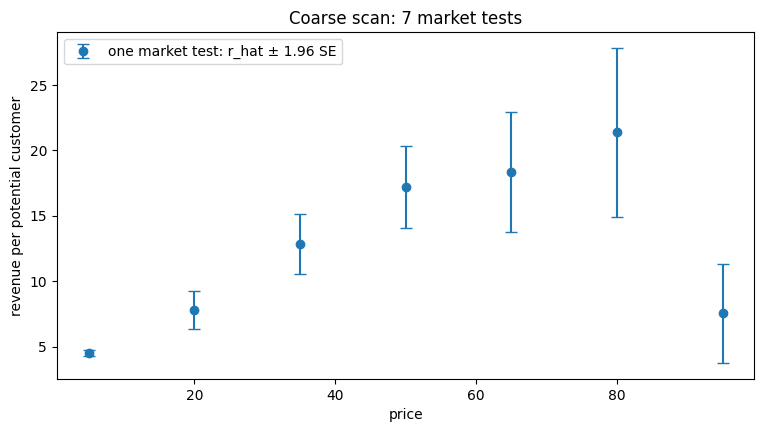

In [84]:
# use in the lab (except the true-curve line)
scan_prices = np.arange(5, 101, 15.0)
scan = {P: run_test(demand, P, data) for P in scan_prices}

r_hats = np.array([P * scan[P].mean() for P in scan_prices])
ses = np.array([se_formula(scan[P], P) for P in scan_prices])

grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o", capsize=4, label="one market test: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

Following the course scan, I notice the range of prices between 65 and 80 seems to be the location of the peak revenue. The values less than 65 have tighter confidence intervals and continue to drop as the price lowers. After 80, there seems to be a step drop off in revenue. I test between 65 and 80, as the both have wide confidence intervals and are close to where I expect the optimal price to be. I will test the difference between $\hat{r}_{65} - \hat{r}_{80}$ to decide where I should go next.

In [85]:
resp_A = data[80][0]
resp_B = data[65][0]

reps_A = bootstrap_r(resp_A, 80.0)
reps_B = bootstrap_r(resp_B, 65.0)

d, boot, z = diff_ci(resp_B, 65.0, reps_B, resp_A, 80.0, reps_A)
print(f"pooled r_65 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$65', '$80')}")

pooled r_65 - r_80 = -3.05
  95% CI, bootstrap: (-10.95, 4.59)  ->  can't tell (interval contains 0)


I find we do not have enough data to determine if the difference is significant. I take another market test and check again.

In [86]:
pool_A = np.concatenate([resp_A, run_test(demand, 80.0, data)])
pool_reps_A = bootstrap_r(pool_A, 80.0)

d, boot, z = diff_ci(resp_B, 65.0, reps_B, pool_A, 80.0, pool_reps_A)
print(f"pooled r_65 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$65', '$80')}")

pooled r_65 - r_80 = -5.03
  95% CI, bootstrap: (-10.74, 0.62)  ->  can't tell (interval contains 0)


I once again find we do not have enough data to determine if the difference is significant. I notice, though, that the confidence interval for the difference shrank quite a bit after pooling, and the upper bound is quickly approaching 0. This leads me to believe it may be beneficial to pool again.

In [88]:
pool_B = np.concatenate([resp_B, run_test(demand, 65.0, data)])
pool_reps_B = bootstrap_r(pool_B, 65.0)

d, boot, z = diff_ci(pool_B, 65.0, pool_reps_B, pool_A, 80.0, pool_reps_A)
print(f"pooled r_65 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$65', '$80')}")

pooled r_65 - r_80 = -5.84
  95% CI, bootstrap: (-10.30, -1.09)  ->  $80 earns more


I now find a price of \$80 earns more revenue than a price of \$65 since 0 is not in the confidence interval and both bounds are negative. I will now compare my samples for \$80 with a value closer to \$80. I choose \$75.

In [89]:
resp_B = run_test(demand, 75.0, data)
reps_B = bootstrap_r(resp_B, 75.0)

d, boot, z = diff_ci(resp_B, 75.0, reps_B, pool_A, 80.0, pool_reps_A)
print(f"pooled r_75 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$75', '$80')}")

pooled r_75 - r_80 = -3.34
  95% CI, bootstrap: (-9.52, 2.77)  ->  can't tell (interval contains 0)


 I find that we do not have enough data to determine if the difference is significant. I take another market test and check again.

In [90]:
pool_C = np.concatenate([resp_B, run_test(demand, 75.0, data)])
pool_reps_C = bootstrap_r(pool_C, 75.0)

d, boot, z = diff_ci(pool_C, 75.0, pool_reps_C, pool_A, 80.0, pool_reps_A)
print(f"pooled r_75 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$75', '$80')}")

pooled r_75 - r_80 = -3.83
  95% CI, bootstrap: (-8.54, 0.81)  ->  can't tell (interval contains 0)


I once again find we do not have enough data to determine if the difference is significant. The confidence interval for the difference shrank quite a bit after pooling, though, and the upper bound is quickly approaching 0. This leads me to believe it may be beneficial to pool again.

In [91]:
pool_C = np.concatenate([pool_C, run_test(demand, 75.0, data)])
pool_reps_C = bootstrap_r(pool_C, 75.0)

d, boot, z = diff_ci(pool_C, 75.0, pool_reps_C, pool_A, 80.0, pool_reps_A)
print(f"pooled r_75 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$75', '$80')}")

pooled r_75 - r_80 = -3.46
  95% CI, bootstrap: (-7.60, 0.63)  ->  can't tell (interval contains 0)


Still not enough data to determine any difference. My upper bound is still closing in on 0, though, so I will try again.

In [93]:
pool_A = np.concatenate([pool_A, run_test(demand, 80.0, data)])
pool_reps_A = bootstrap_r(pool_A, 80.0)

d, boot, z = diff_ci(pool_C, 75.0, pool_reps_C, pool_A, 80.0, pool_reps_A)
print(f"pooled r_75 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$75', '$80')}")

pooled r_75 - r_80 = -3.10
  95% CI, bootstrap: (-6.20, 0.08)  ->  can't tell (interval contains 0)


Not enough data to determine anything, but the upper bound is continuing to shrink. One more pool should be enough data to make a conclusion.

In [94]:
pool_A = np.concatenate([pool_A, run_test(demand, 80.0, data)])
pool_reps_A = bootstrap_r(pool_A, 80.0)

d, boot, z = diff_ci(pool_C, 75.0, pool_reps_C, pool_A, 80.0, pool_reps_A)
print(f"pooled r_75 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$75', '$80')}")

pooled r_75 - r_80 = -2.87
  95% CI, bootstrap: (-5.67, -0.08)  ->  $80 earns more


I now find a price of \$80 earns more revenue than a price of \$75 since 0 is not in the confidence interval and both bounds are negative. Since \$75 is relatively close to \$80, I feel there is no need to test any more values. I found in my tests that values lower than \$80 produces less revenue, and my coarse scan showed a large drop off in revenue for prices above \$80, so I will choose \$80 as my final recommended price.

In [95]:
tests_run(data)

14

My final price is \$80. I ran a total of 14 market tests. Full write up can be found in my git repo.